# Generalising EEG-Based Seizure Prediction: Results Showcase
This notebook visualizes the core findings from the Leave-One-Patient-Out (LOPO) cross-validation and the Cross-Dataset domain shift experiments.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# Define paths to the results data
RESULTS_DIR = Path("../data/results")

## 1. Patient-Independent Generalization (CHB-MIT)
How well does the model predict seizures on an *unseen* patient after training on a cohort of other patients? We compare baseline statistical models against the 1D-CNN.

C:\Users\hp\AppData\Local\Temp\ipykernel_11840\2565556764.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chb_results, x='model', y='auc_mean', ax=axes[0], palette='Blues_d')
C:\Users\hp\AppData\Local\Temp\ipykernel_11840\2565556764.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chb_results, x='model', y='recall_mean', ax=axes[1], palette='Oranges_d')


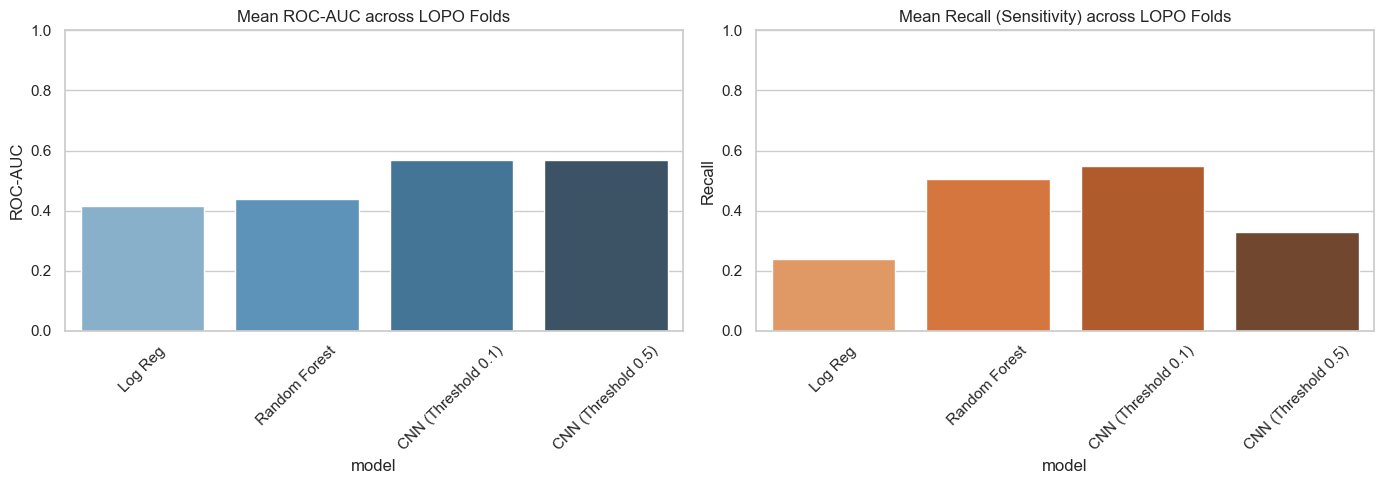

,model,accuracy_mean,f1_mean,recall_mean,auc_mean
0,Log Reg,0.614136,0.120942,0.239307,0.416215
1,Random Forest,0.432770,0.160259,0.503771,0.437521
2,CNN (Threshold 0.1),0.571208,0.192382,0.548841,0.568471
3,CNN (Threshold 0.5),0.710434,0.158311,0.329177,0.568471


In [2]:
# Load CHB-MIT comparison data
chb_results = pd.read_csv(RESULTS_DIR / "table_08_final_chb_comparison.csv")

# Clean up model names for plotting
chb_results['model'] = chb_results['model'].replace({
    'Logistic Regression': 'Log Reg',
    'Random Forest (0.1)': 'Random Forest',
    'CNN (0.5)': 'CNN (Threshold 0.5)',
    'CNN (0.1)': 'CNN (Threshold 0.1)'
})

# Plotting AUC and Recall
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=chb_results, x='model', y='auc_mean', ax=axes[0], palette='Blues_d')
axes[0].set_title('Mean ROC-AUC across LOPO Folds')
axes[0].set_ylabel('ROC-AUC')
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=chb_results, x='model', y='recall_mean', ax=axes[1], palette='Oranges_d')
axes[1].set_title('Mean Recall (Sensitivity) across LOPO Folds')
axes[1].set_ylabel('Recall')
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Display the raw table
display(chb_results[['model', 'accuracy_mean', 'f1_mean', 'recall_mean', 'auc_mean']])

## 2. Cross-Dataset Transfer (CHB-MIT $\rightarrow$ Siena Scalp EEG)
When taking a model trained exclusively on CHB-MIT (Boston) and evaluating it zero-shot on Siena (Italy), the model suffers from domain shift due to differing hardware, sampling rates, and clinical environments. Fine-tuning on a small subset of the target domain recovers performance.

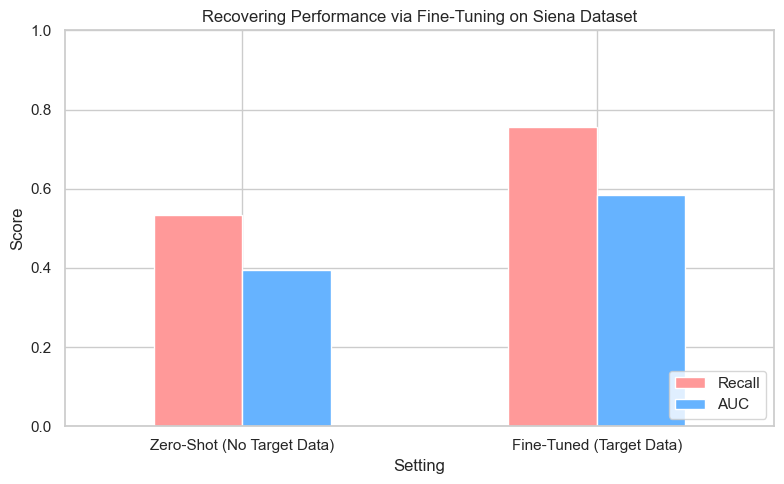

,Setting,Recall,AUC
0,Zero-Shot (No Target Data),0.532853,0.395122
1,Fine-Tuned (Target Data),0.755294,0.583285


In [3]:
# Load Siena Transfer and Fine-tuning data
transfer_results = pd.read_csv(RESULTS_DIR / "table_09_chb_to_siena_transfer_results.csv")
finetune_results = pd.read_csv(RESULTS_DIR / "table_10_fine_tuning_results.csv")

# Extract the relevant CNN (Threshold 0.1) metrics for a clear comparison
zero_shot = finetune_results[finetune_results['model'] == 'CNN CHB→Siena zero-shot (0.1)'].iloc[0]
fine_tuned = finetune_results[finetune_results['model'] == 'CNN CHB→Siena fine-tuned (0.1)'].iloc[0]

comparison_df = pd.DataFrame([
    {'Setting': 'Zero-Shot (No Target Data)', 'Recall': zero_shot['recall'], 'AUC': zero_shot['auc']},
    {'Setting': 'Fine-Tuned (Target Data)', 'Recall': fine_tuned['recall'], 'AUC': fine_tuned['auc']}
])

# Plotting the recovery
fig, ax = plt.subplots(figsize=(8, 5))

comparison_df.set_index('Setting').plot(kind='bar', ax=ax, color=['#ff9999', '#66b3ff'])
ax.set_title('Recovering Performance via Fine-Tuning on Siena Dataset')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

display(comparison_df)